# Assignment 2
**Student:** Juan Camilo Chirivi  
**ID:** 9115141

**Git repo:** https://github.com/jcamilochirivi/Assignment2_AI-Algorithms-N-Math.git

## Setup
Install all packages used here. `%pip` installs them in the notebook's current Python environment.
If Jupyter asks for a kernel restart after installation, restart it and run the cells again.

In [23]:
%pip install -q numpy pandas matplotlib scikit-learn xgboost nbconvert

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score
from xgboost import XGBRegressor

# Support running from the project folder or the notebooks folder.
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data_path = root / 'data' / 'housing.csv'
output_dir = root / 'outputs'
output_dir.mkdir(exist_ok=True)

## Question 1 — Preprocess the data

The data is separated by spaces and has no headers, added the names of the columns. Then check if there are missing data or repeated rows.

Missing target values: 0
Rows and columns: (506, 14)
Missing input values: 0
Duplicate rows: 0


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


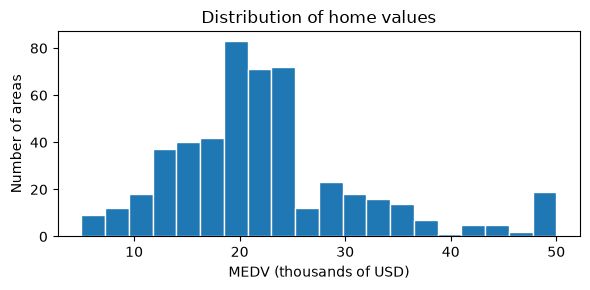

In [25]:
# Read all rows: this file has spaces, not commas, and no header.
columns = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE',
           'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
df = pd.read_csv(data_path, sep=r'\s+', header=None, names=columns)
df = df.apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)

# A row without the true price cannot be used for training or testing.
print('Missing target values:', df['MEDV'].isna().sum())
df = df.dropna(subset=['MEDV'])
print('Rows and columns:', df.shape)
print('Missing input values:', df.drop(columns='MEDV').isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
display(df.head())

# Show the prices before building the models.
df['MEDV'].plot.hist(bins=20, edgecolor='white', figsize=(6, 3))
plt.title('Distribution of home values')
plt.xlabel('MEDV (thousands of USD)')
plt.ylabel('Number of areas')
plt.tight_layout()
plt.show()

## Question 2 — Split the data
**Task:** Use 80% of the samples for training.

The data is divided according to what is indicated in the assingment, 80% so that the models learn and 20% to check their results, additionally the replacement of possible missing data is prepared and we adjust the characteristics to a similar scale.

In [26]:
# Separate the inputs from the value we want to predict.
X = df.drop(columns='MEDV')
y = df['MEDV']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.8, random_state=42
)

# Check outliers using training data only.
q1, q3 = X_train.quantile(0.25), X_train.quantile(0.75)
iqr = q3 - q1
outliers = ((X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)).sum()
display(outliers.rename('Training outlier count').to_frame().T)

# Learn the replacement values and scaling from training inputs only.
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(imputer.fit_transform(X_train))
X_test_scaled = scaler.transform(imputer.transform(X_test))
print(f'Training rows: {len(X_train)} | Test rows: {len(X_test)}')

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
Training outlier count,61,36,0,29,0,24,0,3,0,0,0,63,7


Training rows: 404 | Test rows: 102


## Question 3 — Train the models
**Task:** Train multiple linear regression, XGBoost, a decision tree, random forest, logistic regression, Lasso (L1), and Ridge (L2).

every process receives exactly the same training data and looks for relationships between the characteristics of a zone and its housing value. Each model learns or works in a different way.

In [27]:
# Create the six models that can predict a continuous price directly.
models = {
    'Linear_regression': LinearRegression(),
    'XGBoost': XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05,
                            objective='reg:squarederror', random_state=42, n_jobs=2),
    'Decision_tree': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random_forest': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=2),
    'Lasso_L1': Lasso(alpha=0.1, max_iter=10000),
    'Ridge_L2': Ridge(alpha=1.0)
}

# Train each model using the same training data.
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
print('Six regression models trained.')

Six regression models trained.


### Logistic regression: an explicit adaptation

Logistic regression predicts groups rather than exact prices, so the average price of training was used to create two groups: low and high. The model predicts the probability of each group. In the next cell, the probabilities are combined with each group’s average training price to estimate a price, which results in always being between the averages of the two groups, so you cannot predict very low or very high prices. 

In [28]:
# Define price groups using only training prices.
price_threshold = y_train.median()
train_groups = (y_train >= price_threshold).astype(int)
test_groups = (y_test >= price_threshold).astype(int)

# Learn to classify areas into the two price groups.
logistic = LogisticRegression(max_iter=2000, random_state=42)
logistic.fit(X_train_scaled, train_groups)
group_prices = y_train.groupby(train_groups).mean().reindex(logistic.classes_).to_numpy()

print(f'High-price group starts at MEDV = {price_threshold:.2f}')
print('Training group averages:', group_prices.round(2))
print(f'Logistic classification accuracy: {accuracy_score(test_groups, logistic.predict(X_test_scaled)):.2%}')

High-price group starts at MEDV = 21.60
Training group averages: [16.08 29.44]
Logistic classification accuracy: 87.25%


## Question 4 — Predict the test prices
**Task:** Predict MEDV on the test data with all models.

This cell uses the models requested in question 3 to predict values of test data that were not in training. So a function is built that brings together the predictions of all models, including the approximation of logistic regression. 

The table at the end of the cell shows actual values and predicted values so that you can compare model responses for a given zone. We keep the initial data to keep each prediction with the correct data.

In [29]:
def predict_prices(processed_inputs):
    # Get direct price predictions from the six regressors.
    predictions = {name: model.predict(processed_inputs) for name, model in models.items()}
    # Convert logistic group probabilities into approximate prices.
    predictions['Logistic_price_approx'] = logistic.predict_proba(processed_inputs) @ group_prices
    return predictions

# Keep the actual values and all predictions in the same row order.
test_predictions = predict_prices(X_test_scaled)
prediction_table = pd.DataFrame({'Actual_MEDV': y_test})
for name, values in test_predictions.items():
    prediction_table[name] = values
prediction_table.index.name = 'Original_row'
display(prediction_table.head().round(2))

,Actual_MEDV,Linear_regression,XGBoost,Decision_tree,Random_forest,Lasso_L1,Ridge_L2,Logistic_price_approx
Original_row,,,,,,,,
173,23.6,29.00,23.410000,22.73,22.87,28.62,28.97,28.05
274,32.4,36.03,30.660000,30.05,30.86,34.64,35.97,29.42
491,13.6,14.82,16.730000,19.73,16.79,17.54,14.93,16.18
72,22.8,25.03,23.940001,20.36,23.54,24.89,25.02,28.48
452,16.1,18.77,17.120001,15.91,16.83,18.59,18.76,17.72


## Question 5 — Test a new sample
**Task:** Build a predictive system that accepts a new sample and predicts MEDV.

This is a made-up example with the same 13 inputs

The table will show the result in thousands of dollars and also converted to dollars to check that the system accepts new information and produces a response. Since we do not know the actual price of the example, it cannot be used to determine how correct the prediction is

In [30]:
# Enter one new example in the original units.
new_sample = pd.DataFrame([{
    'CRIM': 0.10, 'ZN': 20.0, 'INDUS': 5.0, 'CHAS': 0,
    'NOX': 0.50, 'RM': 6.5, 'AGE': 50.0, 'DIS': 4.5,
    'RAD': 4, 'TAX': 300.0, 'PTRATIO': 18.0, 'B': 390.0, 'LSTAT': 10.0
}], columns=X.columns)

# Apply the existing preprocessing; do not fit it again.
new_scaled = scaler.transform(imputer.transform(new_sample))
new_results = pd.DataFrame(predict_prices(new_scaled)).T
new_results.columns = ['Predicted_MEDV']
new_results['Estimated_USD'] = new_results['Predicted_MEDV'] * 1000
display(new_results.round(2))

,Predicted_MEDV,Estimated_USD
Linear_regression,25.57,25569.24
XGBoost,21.68,21678.07
Decision_tree,22.73,22726.19
Random_forest,22.65,22646.00
Lasso_L1,25.55,25546.48
Ridge_L2,25.58,25576.61
Logistic_price_approx,26.86,26861.18


## Question 6 — Compare the results
**Task:** Measure performance, find the best model, and summarize MAE, R², and RMSE for all models.

- **MAE** is the average size of the error. 
- **RMSE** gives more weight to large errors. Lower is better for both, and both use thousands of dollars.
- **R²** measures how well predictions explain price differences: 1 is perfect, 0 matches the test-mean baseline, and it can be negative.

Regression has no standard classification accuracy percentage. Here, **highest R²** defines the best price model, as an interpretation of “highest accuracy.”

At the end the results are organized by R2 and showed which one got the best result in this division of the data.

In [31]:
# Compare every set of price predictions with the same true test prices.
scores = []
for name, predicted in test_predictions.items():
    scores.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predicted),
        'R2': r2_score(y_test, predicted),
        'RMSE': np.sqrt(mean_squared_error(y_test, predicted))
    })
results = pd.DataFrame(scores).set_index('Model').sort_values('R2', ascending=False)
display(results.round(3))

# Summarize the best result on this test split.
best_name = results.index[0]
best = results.iloc[0]
print(f'Best model by R2: {best_name} (R2 = {best.R2:.3f}).')
print(f'MAE = {best.MAE:.2f} thousand USD, about ${best.MAE * 1000:,.0f}.')
print(f'RMSE = {best.RMSE:.2f} thousand USD.')

,MAE,R2,RMSE
Model,,,
XGBoost,2.044,0.894,2.782
Decision_tree,2.308,0.883,2.925
Random_forest,2.046,0.883,2.932
Linear_regression,3.189,0.669,4.929
Ridge_L2,3.186,0.668,4.931
Lasso_L1,3.242,0.650,5.065
Logistic_price_approx,3.945,0.524,5.909


Best model by R2: XGBoost (R2 = 0.894).
MAE = 2.04 thousand USD, about $2,044.
RMSE = 2.78 thousand USD.


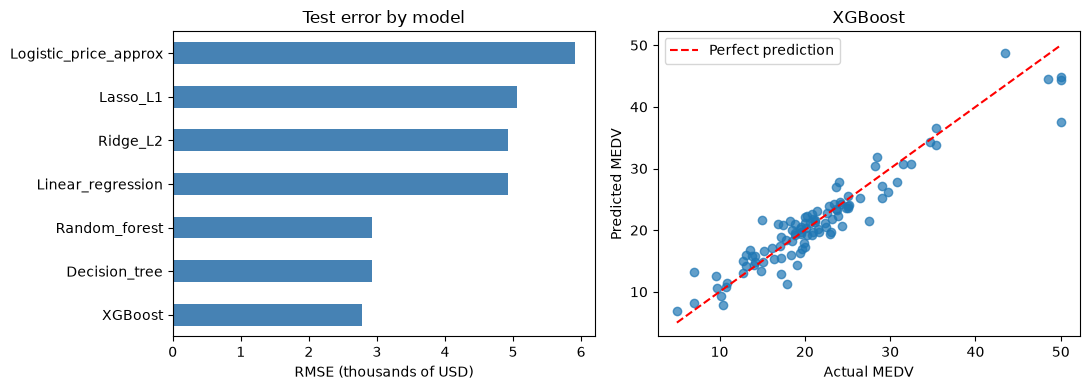

In [32]:
# Compare errors and show how close the best predictions are to real prices.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
results['RMSE'].sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set(title='Test error by model', xlabel='RMSE (thousands of USD)', ylabel='')
axes[1].scatter(y_test, test_predictions[best_name], alpha=0.7)
limits = [min(y_test.min(), np.min(test_predictions[best_name])),
          max(y_test.max(), np.max(test_predictions[best_name]))]
axes[1].plot(limits, limits, 'r--', label='Perfect prediction')
axes[1].set(title=best_name, xlabel='Actual MEDV', ylabel='Predicted MEDV')
axes[1].legend()
plt.tight_layout()
plt.show()

The points close to the dotted line have a lower margin of error, so a greater distance means a greater error, these graphs help us identify the best model for this division, The first compares the RMSE of the models: a shorter bar represents a minor error. The second compares the actual values with the predictions of the model that obtained the largest R². does not mean it is the best for all types of data, the results can vary depending on the dataset


## Question 7 — Save the predictions
**Task:** Save test predictions for all models in one CSV file.

The information is saved in a file called test_predictions_all_models.csv, within the folder named outputs. Each row contains the original index, the actual value, and corresponding predictions.

In [33]:
# Save every test prediction together in one file.
csv_path = output_dir / 'test_predictions_all_models.csv'
prediction_table.to_csv(csv_path, float_format='%.6f')
print(f'Saved {len(prediction_table)} test rows to: {csv_path}')

Saved 102 test rows to: d:\Conestoga\Algo and math\Assignment 2\Assignment2_AI-Algorithms-N-Math\outputs\test_predictions_all_models.csv
